# 14 · Cybersecurity: state estimation, bad-data detection and stealthy false-data injection
**Level 5 · Security of digitalised grids** &nbsp;|&nbsp; Course link: *Module 5 – cybersecurity of energy systems:
IT vs OT, IEC 61850, the CIA triad, false-data-injection attacks and data-driven detection*

Control rooms do not see the grid directly. They run **state estimation**: a least-squares fit of the grid state to
hundreds of noisy measurements, with a statistical **bad-data detector** that flags inconsistent measurements. Every
downstream decision (dispatch, security assessment, markets) uses this estimate, which makes it a prime target.

| CIA goal | in a power system | example attack |
|---|---|---|
| **C**onfidentiality | grid data, customer data stay private | reconnaissance, smart-meter data theft |
| **I**ntegrity | measurements and commands are genuine | **false data injection** (this notebook), command spoofing |
| **A**vailability | data and control arrive in time | denial of service on SCADA / IEC 61850 GOOSE messages |

In OT (operational technology) the priority order is **A > I > C**, the reverse of office IT: a grid must keep
running. IEC 61850 substation messages (GOOSE, sampled values) were designed for speed, not security; IEC 62351 adds
authentication. Here we study integrity attacks on the IEEE 14-bus system.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pandapower as pp, pandapower.networks as pn
from pandapower.pypower.idx_brch import F_BUS, T_BUS, BR_X, TAP
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import roc_auc_score
from energy_ai import gb_dataset, clean_load, set_seed, style
style(); set_seed(0)
rng = np.random.default_rng(0)

## 1. The DC measurement model $z = H\theta + e$
State $\theta$: bus voltage angles (slack bus fixed at 0). Measurements: active power flow on every branch and active
injection at every bus. In the DC approximation they are linear in the angles:
$P_{ij} = (\theta_i-\theta_j)/x_{ij}$ and $P_i = \sum_j B_{ij}\theta_j$.

In [2]:
net = pn.case14(); pp.rundcpp(net)
ppc = net._ppc; br = ppc["branch"]; base = ppc["baseMVA"]
nb, nl = ppc["bus"].shape[0], br.shape[0]
f, t = br[:, F_BUS].real.astype(int), br[:, T_BUS].real.astype(int)
tap = br[:, TAP].real; tap[tap == 0] = 1
b = 1 / (br[:, BR_X].real * tap)
A = np.zeros((nl, nb)); A[np.arange(nl), f] = 1; A[np.arange(nl), t] = -1
Bf = b[:, None] * A                         # branch flows = Bf θ
Bbus = A.T @ Bf                             # injections  = Bbus θ
slack = int(net.ext_grid.bus.iloc[0])
keep = [i for i in range(nb) if i != slack]
H = np.vstack([Bf, Bbus])[:, keep]          # m × n
m, n = H.shape
print(f"{nb} buses, {nl} branches | measurements m = {m}, states n = {n}, redundancy m/n = {m / n:.1f}")

14 buses, 20 branches | measurements m = 34, states n = 13, redundancy m/n = 2.6


## 2. Realistic operating points
60 days of hourly operation: every load follows the real GB demand curve, with individual random deviations; the
generators share the total in proportion to their base-case output.

In [3]:
gb = gb_dataset()
shape, _ = clean_load(gb.load_mw)
shape = (shape.loc["2019-01-07":"2019-03-07"] / shape.loc["2019-01-07":"2019-03-07"].mean()).values
T_h = len(shape)
load_bus = net.load.bus.values; p_load0 = net.load.p_mw.values
gen_bus = np.r_[net.gen.bus.values, net.ext_grid.bus.values]
gen_share = np.r_[np.maximum(net.gen.p_mw.values, 0), net.res_ext_grid.p_mw.values]; gen_share = gen_share / gen_share.sum()

def operating_point(k):
    loads = p_load0 * shape[k] * (1 + 0.05 * rng.standard_normal(len(p_load0)))
    P = np.zeros(nb)
    np.add.at(P, load_bus, -loads)
    np.add.at(P, gen_bus, loads.sum() * gen_share)
    theta = np.zeros(nb); theta[keep] = np.linalg.solve(Bbus[np.ix_(keep, keep)], P[keep] / base)
    return theta[keep]

thetas = np.array([operating_point(k) for k in range(T_h)])
SIGMA = 0.01                                   # measurement noise: 1 MW on a 100 MVA base
W = np.eye(m) / SIGMA ** 2
Z = thetas @ H.T + SIGMA * rng.standard_normal((T_h, m))
print(f"{T_h} hourly snapshots | largest flow {np.abs(Z[:, :nl]).max() * base:.0f} MW")

1440 hourly snapshots | largest flow 201 MW


## 3. Weighted least squares and the χ² bad-data detector
$$\hat\theta = (H^\top W H)^{-1} H^\top W z,\qquad r = z - H\hat\theta,\qquad J(\hat\theta) = r^\top W r \sim \chi^2_{m-n}$$
If the measurements are consistent with physics and the noise model, $J$ follows a chi-square distribution. An
alarm is raised when $J$ exceeds its 99 % quantile (1 % false-alarm rate by design).

In [4]:
G_inv = np.linalg.inv(H.T @ W @ H) @ H.T @ W
def estimate(z):
    th = z @ G_inv.T
    r = z - th @ H.T
    return th, (r ** 2 / SIGMA ** 2).sum(-1)

TAU = stats.chi2.ppf(0.99, m - n)
th_hat, J_normal = estimate(Z)
print(f"threshold χ²(0.99, {m - n}) = {TAU:.1f} | false-alarm rate on normal data: {(J_normal > TAU).mean():.1%}")

threshold χ²(0.99, 21) = 38.9 | false-alarm rate on normal data: 0.8%


## 4. Two attacks
**Naive attack:** the attacker adds 20 MW to three measurements. The measurements no longer fit any physical state, so
the residual explodes.

**Stealthy attack** (Liu, Ning & Reiter, 2009): the attacker who knows $H$ injects $a = Hc$. Then
$z+a = H(\theta + c) + e$ is perfectly consistent with a *different* state: the residual is **unchanged** and the
estimate silently moves by $c$.

J normal = 31.3 | J naive attack = 930  (alarm: True) | J stealthy attack = 31.3 (alarm: False)


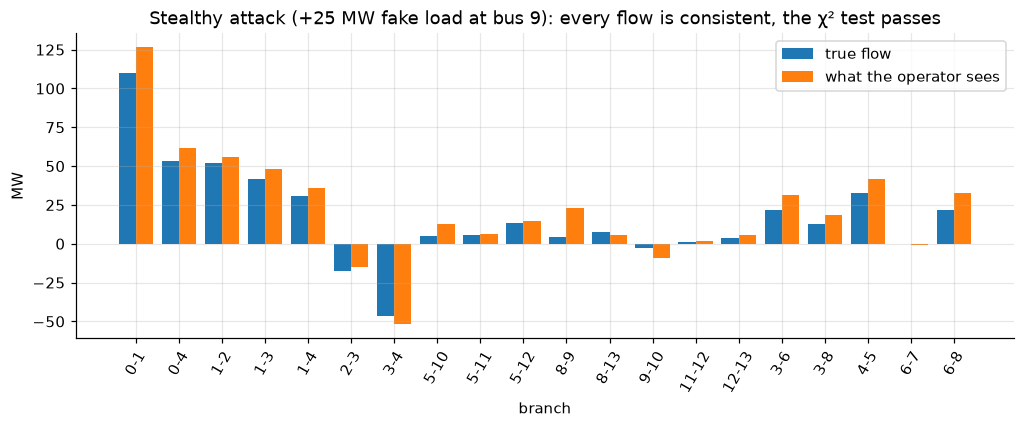

In [5]:
def naive_attack(z):
    a = np.zeros(m); a[rng.choice(m, 3, replace=False)] = 0.2 * rng.choice([-1, 1], 3)
    return z + a

def stealthy_attack(z, bus=None, mw=None):
    """Make the operator believe that the load at `bus` is `mw` MW higher than it is."""
    bus = bus if bus is not None else rng.choice([i for i in keep if i in load_bus])
    mw = mw if mw is not None else rng.uniform(10, 30)
    dP = np.zeros(nb); dP[bus] = -mw / base
    c = np.linalg.solve(Bbus[np.ix_(keep, keep)], dP[keep])
    return z + H @ c, c

k = 100
z_naive = naive_attack(Z[k]); z_stealth, c = stealthy_attack(Z[k], bus=9, mw=25)
_, Jn = estimate(z_naive); th_s, Js = estimate(z_stealth)
print(f"J normal = {J_normal[k]:.1f} | J naive attack = {Jn:.0f}  (alarm: {Jn > TAU}) | J stealthy attack = {Js:.1f} (alarm: {Js > TAU})")

flows_true = (Bf[:, keep] @ thetas[k]) * base
flows_seen = (Bf[:, keep] @ th_s) * base
fig, ax = plt.subplots(figsize=(11, 3.6))
xs = np.arange(nl)
ax.bar(xs - 0.2, flows_true, 0.4, label="true flow"); ax.bar(xs + 0.2, flows_seen, 0.4, label="what the operator sees")
ax.set(xticks=xs, xticklabels=[f"{f[i]}-{t[i]}" for i in range(nl)], ylabel="MW", xlabel="branch",
       title="Stealthy attack (+25 MW fake load at bus 9): every flow is consistent, the χ² test passes"); ax.legend()
plt.xticks(rotation=60); plt.show()

## 5. Detection rates on 60 days of data

In [6]:
def attacked_dataset(kind):
    out, labels = [], []
    for kk in range(T_h):
        if rng.random() < 0.5:
            out.append(naive_attack(Z[kk]) if kind == "naive" else stealthy_attack(Z[kk])[0]); labels.append(1)
        else:
            out.append(Z[kk]); labels.append(0)
    return np.array(out), np.array(labels)

rows = []
for kind in ("naive", "stealthy"):
    Za, ya = attacked_dataset(kind)
    _, J = estimate(Za)
    rows.append({"attack": kind, "χ² detector: attacks detected": (J[ya == 1] > TAU).mean(), "χ² false alarms": (J[ya == 0] > TAU).mean()})
display(pd.DataFrame(rows).set_index("attack").style.format("{:.1%}"))

,χ² detector: attacks detected,χ² false alarms
attack,,
naive,100.0%,1.1%
stealthy,1.1%,0.5%


## 6. Data-driven detection of stealthy attacks
The stealthy attack is consistent with *physics* but not with *history*: loads move together (they follow the same
daily curve), and the attack makes one bus deviate from that pattern. We give a detector the **estimated bus
injections** as a share of total demand, plus the hour of the day, and compare:
* an **unsupervised** detector (isolation forest) trained on normal operation only;
* a **supervised** classifier (gradient boosting) trained on labelled attack examples (e.g. from red-team exercises).

Days 1–30 train the detectors, days 31–40 calibrate the alarm thresholds (1 % false alarms on *unseen* normal data;
calibrating on the training data itself would be over-optimistic), days 41–60 test.

In [7]:
def se_features(Zs):
    th, _ = estimate(Zs)
    P = np.zeros((len(Zs), nb)); P[:, keep] = th @ Bbus[np.ix_(keep, keep)].T
    loads = -P[:, [i for i in np.unique(load_bus)]]
    return np.c_[loads / loads.sum(1, keepdims=True), np.arange(len(Zs)) % 24]

s1, s2 = 30 * 24, 40 * 24
Zs_all, ys_all = attacked_dataset("stealthy")
F_all = se_features(Zs_all)
F_tr, y_tr = F_all[:s1], ys_all[:s1]
F_cal, y_cal = F_all[s1:s2], ys_all[s1:s2]
F_te, y_te = F_all[s2:], ys_all[s2:]

iso = IsolationForest(n_estimators=300, random_state=0).fit(F_tr[y_tr == 0])
thr_iso = np.quantile(-iso.score_samples(F_cal[y_cal == 0]), 0.99)
s_te = -iso.score_samples(F_te)
gbc = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(F_tr, y_tr)
thr_gb = np.quantile(gbc.predict_proba(F_cal[y_cal == 0])[:, 1], 0.99)
p_te = gbc.predict_proba(F_te)[:, 1]
_, J_te = estimate(Zs_all[s2:])
det = pd.DataFrame({
    "χ² bad-data detector": {"attacks detected": (J_te[y_te == 1] > TAU).mean(), "false alarms": (J_te[y_te == 0] > TAU).mean(), "ROC-AUC": roc_auc_score(y_te, J_te)},
    "isolation forest (normal data only)": {"attacks detected": (s_te[y_te == 1] > thr_iso).mean(), "false alarms": (s_te[y_te == 0] > thr_iso).mean(), "ROC-AUC": roc_auc_score(y_te, s_te)},
    "gradient boosting (labelled attacks)": {"attacks detected": (p_te[y_te == 1] > thr_gb).mean(), "false alarms": (p_te[y_te == 0] > thr_gb).mean(), "ROC-AUC": roc_auc_score(y_te, p_te)},
}).T
display(det.style.format({"attacks detected": "{:.1%}", "false alarms": "{:.1%}", "ROC-AUC": "{:.3f}"}))

,attacks detected,false alarms,ROC-AUC
χ² bad-data detector,0.0%,0.8%,0.544
isolation forest (normal data only),53.4%,1.7%,0.952
gradient boosting (labelled attacks),83.2%,0.8%,0.992


## 7. Defence by design: protect a basic measurement set
A stealthy attack needs $a = Hc$ with $a_i = 0$ on every measurement the attacker cannot touch. If the protected rows
$H_p$ (e.g. measurements secured by IEC 62351 authentication or PMUs with GPS) have **full column rank**, the only
solution of $H_p c = 0$ is $c = 0$: no stealthy attack exists. The dimension of the attack space is $n - \text{rank}(H_p)$.

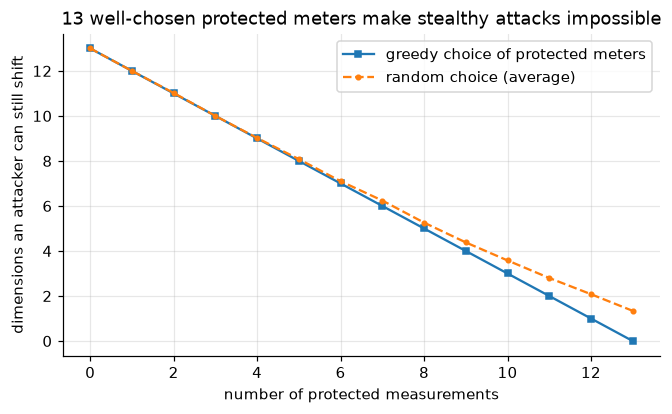

a random set of 13 protected meters closes the attack space in only 9% of the draws; the greedy set always does
protected measurements (greedy): ['flow 0-1', 'flow 0-4', 'flow 1-2', 'flow 1-3', 'flow 5-10', 'flow 5-11', 'flow 5-12', 'flow 8-9', 'flow 8-13', 'flow 9-10', 'flow 3-6', 'flow 3-8', 'flow 6-7']


In [8]:
def attack_space_dim(rows_protected):
    return n - (np.linalg.matrix_rank(H[rows_protected]) if len(rows_protected) else 0)

greedy, dims_greedy = [], [attack_space_dim([])]
for _ in range(n):
    best = max((r for r in range(m) if r not in greedy), key=lambda r: -attack_space_dim(greedy + [r]))
    greedy.append(best); dims_greedy.append(attack_space_dim(greedy))
dims_random = np.mean([[attack_space_dim(list(rng.permutation(m)[:k])) for k in range(n + 1)] for _ in range(50)], axis=0)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(n + 1), dims_greedy, "s-", ms=4, label="greedy choice of protected meters")
ax.plot(range(n + 1), dims_random, "o--", ms=3, label="random choice (average)")
ax.set(xlabel="number of protected measurements", ylabel="dimensions an attacker can still shift",
       title="13 well-chosen protected meters make stealthy attacks impossible"); ax.legend(); plt.show()
full = np.mean([attack_space_dim(list(rng.permutation(m)[:n])) == 0 for _ in range(500)])
print(f"a random set of {n} protected meters closes the attack space in only {full:.0%} of the draws; the greedy set always does")
print("protected measurements (greedy):", [("flow " + f"{f[r]}-{t[r]}") if r < nl else f"injection bus {r - nl}" for r in greedy])

The greedy choice is 13 branch flows that connect all 14 buses without a loop: a **spanning tree** of the grid.
Knowing the flows on a spanning tree pins down every angle difference, so no consistent fake state remains.

## Key takeaways
* The χ² bad-data detector catches gross errors and naive attacks, but an attacker who knows the grid model can craft
  **stealthy** injections $a=Hc$ that are invisible to it, and silently move the operator's picture of the grid.
* Physically consistent is not the same as *normal*: data-driven detectors exploit historical patterns (correlated
  loads, daily cycles) that the attacker did not reproduce. Supervised detectors are stronger but need labelled
  attacks; unsupervised ones need only normal data.
* Prevention beats detection: securing a small, well-chosen set of measurements (rank condition) eliminates the
  stealthy attack space. Combine with IEC 62351 authentication, network segmentation and monitoring (defence in depth).